In [ ]:
from pathlib import Path
import sys

import numpy as np
import pandas as pd
import torch
import cvxpy as cp
import matplotlib.pyplot as plt

# Locate the project root.
current = Path.cwd().resolve()

root = next(
    (
        folder
        for folder in (current, *current.parents)
        if all(
            (folder / name).is_dir()
            for name in [
                "hedging",
                "path simulation",
                "inner maximization",
                "outer minimization",
            ]
        )
    ),
    None,
)

if root is None:
    raise FileNotFoundError(
        f"Could not find awdro from {current}. "
        "Open this notebook inside your awdro project."
    )

for folder in [
    root,
    root / "hedging",
    root / "path simulation",
    root / "inner maximization",
    root / "outer minimization",
]:
    if str(folder) not in sys.path:
        sys.path.insert(0, str(folder))

from Heston import Heston
from SuperhedgingProblem import SuperhedgingProblem
from NonrectangularSolver import NonrectangularSolver
from RectangularSolver import RectangularSolver
from RelaxedSuperhedgingSolver import RelaxedSuperhedgingSolver

# Check that the saved class includes both adaptive methods.
for method in [
    "_build_history_groups",
    "_build_adaptive_gains_matrix",
    "solve_adaptive_hedge_nonrectangular",
    "solve_adaptive_hedge_rectangular",
]:
    if not hasattr(RelaxedSuperhedgingSolver, method):
        raise AttributeError(
            f"Missing method: {method}. "
            "Save the updated class, restart the kernel, and rerun."
        )

if "HIGHS" not in cp.installed_solvers():
    raise RuntimeError(
        "HiGHS is unavailable. Run %pip install highspy, "
        "then restart the kernel."
    )

model = Heston(
    s0=100.0,
    v0=0.04,
    mu=0.0,
    kappa=2.0,
    theta=0.04,
    vol_of_vol=0.3,
    rho=-0.7,
)

print("Project root:", root)
print("Adaptive methods and HiGHS are available.")
print("Heston model initialized.")

Project root: /Users/jacve/Git/awdro
Adaptive methods and HiGHS are available.
Heston model initialized.


In [30]:
import pandas as pd
import matplotlib.pyplot as plt

maturity = 1.0
step_counts = [1, 2, 3]
budgets = [0.0, 0.3, 0.5, 0.7, 1.0, 1.5]
seeds = [42, 43, 44]

reference_branches = 2
strike = 80.0
penalty = 100

capital_bounds = (0.0, 200.0)
holding_bounds = (-3.0, 3.0)


def call_payoff(paths):
    return torch.clamp(paths[:, -1, 0] - strike, min=0.0)


def put_payoff(paths):
    return torch.clamp(strike - paths[:, -1, 0], min=0.0)

def butterfly_payoff(paths):
    stock = paths[:, -1, 0]

    return (
        torch.clamp(stock - 90.0, min=0.0)
        - 2.0 * torch.clamp(stock - 100.0, min=0.0)
        + torch.clamp(stock - 110.0, min=0.0)
    )


def digital_call_payoff(paths):
    stock = paths[:, -1, 0]

    # Pays 10 if the terminal stock is strictly above 100.
    return 10.0 * (stock > 100.0).to(paths.dtype)


payoffs = {
    "European call": call_payoff,
    "Digital call": digital_call_payoff,
}

output_dir = root / "results" / "adaptive_step_sweep"
output_dir.mkdir(parents=True, exist_ok=True)

In [31]:
records = []
completed = 0

total = len(step_counts) * len(budgets) * len(seeds) * len(payoffs)

for n_steps in step_counts:
    trading_times = np.linspace(0.0, maturity, n_steps + 1)

    for seed in seeds:
        settings = {
            "reference_branches": reference_branches,
            "seed": seed,
        }

        for budget in budgets:
            rectangular = RectangularSolver(
                reference_model=model,
                trading_times=trading_times,
                budget=budget,
                discretization=settings,
            )

            nonrectangular = NonrectangularSolver(
                reference_model=model,
                trading_times=trading_times,
                budget=budget,
                discretization=settings,
            )

            # Both optimizations must use the same finite model.
            np.testing.assert_array_equal(
                np.asarray([
                    node["state"] for node in rectangular.reference_nodes
                ]),
                np.asarray([
                    node["state"] for node in nonrectangular.reference_nodes
                ]),
            )

            for t in range(n_steps + 1):
                np.testing.assert_array_equal(
                    rectangular.adversarial_candidates[t],
                    nonrectangular.adversarial_candidates[t],
                )

            for payoff_name, payoff_fn in payoffs.items():
                problem = SuperhedgingProblem(
                    payoff=payoff_fn,
                    trading_times=trading_times,
                )

                outer = RelaxedSuperhedgingSolver(
                    problem=problem,
                    inner_solver=nonrectangular,
                    penalty=penalty,
                )

                nr = outer.solve_adaptive_hedge_nonrectangular(
                    rectangular,
                    capital_bounds,
                    holding_bounds,
                )

                rect = outer.solve_adaptive_hedge_rectangular(
                    rectangular,
                    capital_bounds,
                    holding_bounds,
                )

                gap = rect["value"] - nr["value"]

                tolerance = 1e-4 * max(
                    1.0,
                    abs(rect["value"]),
                    abs(nr["value"]),
                )

                assert gap >= -tolerance, (
                    f"Negative gap beyond tolerance: "
                    f"steps={n_steps}, budget={budget}, "
                    f"seed={seed}, payoff={payoff_name}"
                )

                # With one interval, there is no later kernel to paste.
                # With zero budget, both ambiguity sets reduce to the reference law.
                if n_steps == 1 or budget == 0:
                    np.testing.assert_allclose(
                        rect["value"],
                        nr["value"],
                        rtol=1e-5,
                        atol=1e-4,
                    )

                record = {
                    "payoff": payoff_name,
                    "maturity": maturity,
                    "n_steps": n_steps,
                    "dt": maturity / n_steps,
                    "budget": budget,
                    "seed": seed,
                    "reference_branches": reference_branches,
                    "penalty": penalty,
                    "nonrectangular_value": nr["value"],
                    "rectangular_value": rect["value"],
                    "gap": gap,
                    "nonrectangular_capital": nr["capital"],
                    "rectangular_capital": rect["capital"],
                    "nonrectangular_shortfall": nr["worst_case_shortfall"],
                    "rectangular_shortfall": rect["worst_case_shortfall"],
                    "n_hedge_variables": len(rect["holdings"]),
                }

                for name, answer in [
                    ("nonrectangular", nr),
                    ("rectangular", rect),
                ]:
                    holdings = np.asarray(answer["holdings"])

                    record[f"{name}_capital_at_bound"] = bool(
                        np.isclose(
                            answer["capital"],
                            capital_bounds,
                            rtol=0.0,
                            atol=1e-4,
                        ).any()
                    )

                    record[f"{name}_holding_bound_count"] = int(
                        (
                            np.isclose(
                                holdings, holding_bounds[0],
                                rtol=0.0, atol=1e-4,
                            )
                            | np.isclose(
                                holdings, holding_bounds[1],
                                rtol=0.0, atol=1e-4,
                            )
                        ).sum()
                    )

                records.append(record)

                pd.DataFrame(records).to_csv(
                    output_dir / "raw_results.csv",
                    index=False,
                )

                completed += 1
                print(
                    f"[{completed}/{total}] "
                    f"{payoff_name} | steps={n_steps} | "
                    f"budget={budget:g} | seed={seed} | "
                    f"gap={gap:.6f}"
                )

results = pd.DataFrame(records)
display(results)

[1/108] European call | steps=1 | budget=0 | seed=42 | gap=0.000000
[2/108] Digital call | steps=1 | budget=0 | seed=42 | gap=0.000000
[3/108] European call | steps=1 | budget=0.3 | seed=42 | gap=0.000000
[4/108] Digital call | steps=1 | budget=0.3 | seed=42 | gap=-0.000000
[5/108] European call | steps=1 | budget=0.5 | seed=42 | gap=0.000000
[6/108] Digital call | steps=1 | budget=0.5 | seed=42 | gap=-0.000000
[7/108] European call | steps=1 | budget=0.7 | seed=42 | gap=0.000000
[8/108] Digital call | steps=1 | budget=0.7 | seed=42 | gap=-0.000000
[9/108] European call | steps=1 | budget=1 | seed=42 | gap=0.000000
[10/108] Digital call | steps=1 | budget=1 | seed=42 | gap=-0.000000
[11/108] European call | steps=1 | budget=1.5 | seed=42 | gap=0.000000
[12/108] Digital call | steps=1 | budget=1.5 | seed=42 | gap=-0.000000
[13/108] European call | steps=1 | budget=0 | seed=43 | gap=0.000000
[14/108] Digital call | steps=1 | budget=0 | seed=43 | gap=0.000000
[15/108] European call | step

,payoff,maturity,n_steps,dt,budget,seed,reference_branches,penalty,nonrectangular_value,rectangular_value,gap,nonrectangular_capital,rectangular_capital,nonrectangular_shortfall,rectangular_shortfall,n_hedge_variables,nonrectangular_capital_at_bound,nonrectangular_holding_bound_count,rectangular_capital_at_bound,rectangular_holding_bound_count
0,European call,1.0,1,1.000000,0.0,42,2,100,8.148451,8.148451,0.000000e+00,8.148451,8.148451,0.0,0.0,1,False,1,False,1
1,Digital call,1.0,1,1.000000,0.0,42,2,100,0.000000,0.000000,0.000000e+00,-0.000000,-0.000000,0.0,0.0,1,True,1,True,1
2,European call,1.0,1,1.000000,0.3,42,2,100,8.148451,8.148451,0.000000e+00,8.148451,8.148451,0.0,-0.0,1,False,1,False,1
3,Digital call,1.0,1,1.000000,0.3,42,2,100,0.000000,-0.000000,-0.000000e+00,-0.000000,-0.000000,0.0,-0.0,1,True,1,True,1
4,European call,1.0,1,1.000000,0.5,42,2,100,8.148451,8.148451,0.000000e+00,8.148451,8.148451,0.0,-0.0,1,False,1,False,1
...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...
103,Digital call,1.0,3,0.333333,0.7,44,2,100,7.583913,7.583913,0.000000e+00,7.583913,7.583913,0.0,-0.0,11,False,0,False,0
104,European call,1.0,3,0.333333,1.0,44,2,100,20.376925,20.376925,0.000000e+00,20.376925,20.376925,0.0,-0.0,11,False,0,False,0
105,Digital call,1.0,3,0.333333,1.0,44,2,100,7.583913,7.583913,0.000000e+00,7.583913,7.583913,0.0,-0.0,11,False,0,False,0
106,European call,1.0,3,0.333333,1.5,44,2,100,20.376925,20.376925,-3.552714e-15,20.376925,20.376925,0.0,-0.0,11,False,0,False,0


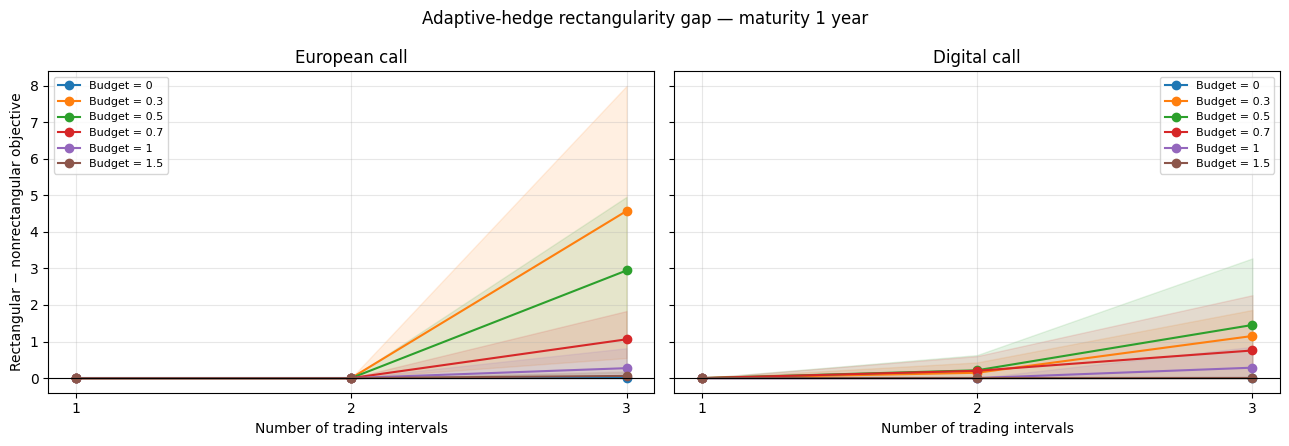

In [32]:
summary = (
    results.groupby(
        ["payoff", "n_steps", "budget"],
        as_index=False,
    )
    .agg(
        nonrectangular_mean=("nonrectangular_value", "mean"),
        rectangular_mean=("rectangular_value", "mean"),
        gap_mean=("gap", "mean"),
        gap_min=("gap", "min"),
        gap_max=("gap", "max"),
        gap_std=("gap", "std"),
    )
)

summary.to_csv(output_dir / "summary.csv", index=False)

fig, axes = plt.subplots(1, 2, figsize=(13, 4.5), sharey=True)

for ax, payoff_name in zip(axes, payoffs):
    payoff_data = summary[summary["payoff"] == payoff_name]

    for budget in budgets:
        data = (
            payoff_data[payoff_data["budget"] == budget]
            .sort_values("n_steps")
        )

        line = ax.plot(
            data["n_steps"],
            data["gap_mean"],
            marker="o",
            label=f"Budget = {budget:g}",
        )[0]

        ax.fill_between(
            data["n_steps"].to_numpy(),
            data["gap_min"].to_numpy(),
            data["gap_max"].to_numpy(),
            color=line.get_color(),
            alpha=0.12,
        )

    ax.set_title(payoff_name)
    ax.set_xlabel("Number of trading intervals")
    ax.set_xticks(step_counts)
    ax.axhline(0.0, color="black", linewidth=0.8)
    ax.grid(alpha=0.3)
    ax.legend(fontsize=8)

axes[0].set_ylabel("Rectangular − nonrectangular objective")

fig.suptitle(f"Adaptive-hedge rectangularity gap — maturity {maturity:g} year")
fig.tight_layout()

fig.savefig(
    output_dir / "gap_vs_steps.png",
    dpi=200,
    bbox_inches="tight",
)

plt.show()

In [33]:
penalties = [2.0, 5.0, 10.0, 25.0, 50.0]
seeds = [42, 43, 44]

maturity = 1.0
n_steps = 2
budget = 1.0
reference_branches = 2

trading_times = np.linspace(0.0, maturity, n_steps + 1)

capital_bounds = (0.0, 50.0)
holding_bounds = (-2.0, 2.0)

penalty_records = []

In [34]:
for seed in seeds:
    settings = {
        "reference_branches": reference_branches,
        "seed": seed,
    }

    rectangular = RectangularSolver(
        model, trading_times, budget, settings
    )
    nonrectangular = NonrectangularSolver(
        model, trading_times, budget, settings
    )

    np.testing.assert_array_equal(
        np.asarray([node["state"] for node in rectangular.reference_nodes]),
        np.asarray([node["state"] for node in nonrectangular.reference_nodes]),
    )

    for payoff_name, payoff_fn in payoffs.items():
        problem = SuperhedgingProblem(
            payoff=payoff_fn,
            trading_times=trading_times,
        )

        for penalty in penalties:
            outer = RelaxedSuperhedgingSolver(
                problem=problem,
                inner_solver=nonrectangular,
                penalty=penalty,
            )

            nr = outer.solve_adaptive_hedge_nonrectangular(
                rectangular, capital_bounds, holding_bounds
            )
            rect = outer.solve_adaptive_hedge_rectangular(
                rectangular, capital_bounds, holding_bounds
            )

            gap = rect["value"] - nr["value"]
            tolerance = 1e-4 * max(
                1.0, abs(rect["value"]), abs(nr["value"])
            )

            assert gap >= -tolerance

            record = {
                "payoff": payoff_name,
                "seed": seed,
                "penalty": penalty,
                "budget": budget,
                "n_steps": n_steps,
                "maturity": maturity,
                "nonrectangular_value": nr["value"],
                "rectangular_value": rect["value"],
                "gap": gap,
                "nonrectangular_shortfall": nr["worst_case_shortfall"],
                "rectangular_shortfall": rect["worst_case_shortfall"],
                "nonrectangular_capital": nr["capital"],
                "rectangular_capital": rect["capital"],
            }

            for name, answer in [
                ("nonrectangular", nr),
                ("rectangular", rect),
            ]:
                record[f"{name}_at_bound"] = bool(
                    np.isclose(
                        answer["capital"],
                        capital_bounds,
                        rtol=0.0,
                        atol=1e-4,
                    ).any()
                    or np.isclose(
                        np.asarray(answer["holdings"])[:, None],
                        np.asarray(holding_bounds)[None, :],
                        rtol=0.0,
                        atol=1e-4,
                    ).any()
                )

            penalty_records.append(record)

            print(
                f"{payoff_name} | seed={seed} | "
                f"penalty={penalty:g} | gap={gap:.6f}"
            )

penalty_results = pd.DataFrame(penalty_records)
display(penalty_results)

European call | seed=42 | penalty=2 | gap=0.000381
European call | seed=42 | penalty=5 | gap=0.000000
European call | seed=42 | penalty=10 | gap=0.000000
European call | seed=42 | penalty=25 | gap=0.000000
European call | seed=42 | penalty=50 | gap=0.000000
Digital call | seed=42 | penalty=2 | gap=0.000000
Digital call | seed=42 | penalty=5 | gap=0.000000
Digital call | seed=42 | penalty=10 | gap=0.000000
Digital call | seed=42 | penalty=25 | gap=0.000000
Digital call | seed=42 | penalty=50 | gap=-0.000000
European call | seed=43 | penalty=2 | gap=0.003635
European call | seed=43 | penalty=5 | gap=0.009088
European call | seed=43 | penalty=10 | gap=0.000000
European call | seed=43 | penalty=25 | gap=0.000000
European call | seed=43 | penalty=50 | gap=0.000000
Digital call | seed=43 | penalty=2 | gap=0.096735
Digital call | seed=43 | penalty=5 | gap=0.241838
Digital call | seed=43 | penalty=10 | gap=0.470710
Digital call | seed=43 | penalty=25 | gap=0.628397
Digital call | seed=43 | pen

,payoff,seed,penalty,budget,n_steps,maturity,nonrectangular_value,rectangular_value,gap,nonrectangular_shortfall,rectangular_shortfall,nonrectangular_capital,rectangular_capital,nonrectangular_at_bound,rectangular_at_bound
0,European call,42,2.0,1.0,2,1.0,15.221954,15.222335,3.808911e-04,0.144126,0.143913,14.933702,14.934508,True,True
1,European call,42,5.0,1.0,2,1.0,15.649470,15.649470,0.000000e+00,0.140091,0.140091,14.949013,14.949013,True,True
2,European call,42,10.0,1.0,2,1.0,16.349927,16.349927,0.000000e+00,0.140091,0.140091,14.949013,14.949013,True,True
3,European call,42,25.0,1.0,2,1.0,18.254981,18.254981,0.000000e+00,0.000000,-0.000000,18.254981,18.254981,True,True
4,European call,42,50.0,1.0,2,1.0,18.254981,18.254981,0.000000e+00,0.000000,-0.000000,18.254981,18.254981,True,True
5,Digital call,42,2.0,1.0,2,1.0,0.281933,0.281933,0.000000e+00,0.140966,0.140966,-0.000000,-0.000000,True,True
6,Digital call,42,5.0,1.0,2,1.0,0.704832,0.704832,0.000000e+00,0.140966,0.140966,-0.000000,-0.000000,True,True
7,Digital call,42,10.0,1.0,2,1.0,1.409664,1.409664,0.000000e+00,0.140966,0.140966,-0.000000,-0.000000,True,True
8,Digital call,42,25.0,1.0,2,1.0,3.326617,3.326617,0.000000e+00,0.000000,-0.000000,3.326617,3.326617,True,True
9,Digital call,42,50.0,1.0,2,1.0,3.326617,3.326617,-4.440892e-16,0.000000,-0.000000,3.326617,3.326617,True,True


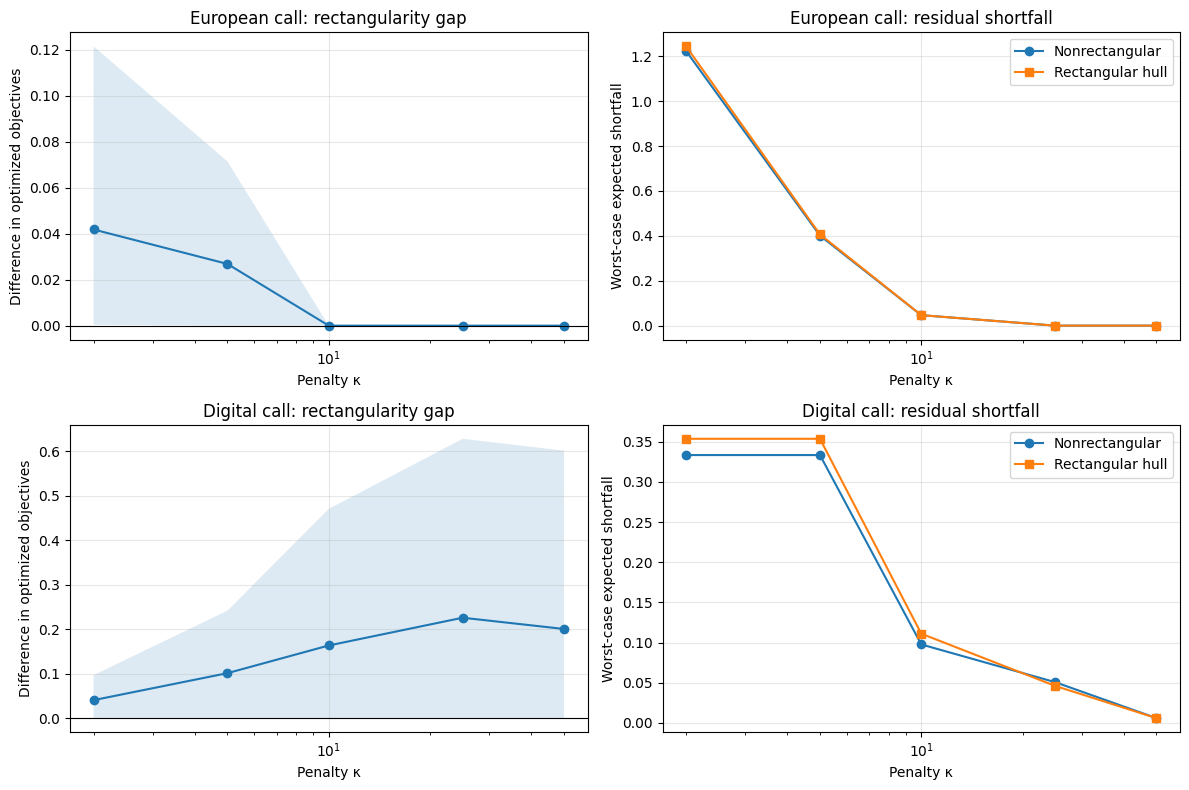

In [35]:
penalty_summary = (
    penalty_results.groupby(["payoff", "penalty"], as_index=False)
    .agg(
        gap_mean=("gap", "mean"),
        gap_min=("gap", "min"),
        gap_max=("gap", "max"),
        nonrectangular_shortfall=("nonrectangular_shortfall", "mean"),
        rectangular_shortfall=("rectangular_shortfall", "mean"),
    )
)

fig, axes = plt.subplots(
    len(payoffs),
    2,
    figsize=(12, 4 * len(payoffs)),
    squeeze=False,
)

for row, payoff_name in enumerate(payoffs):
    data = (
        penalty_summary[penalty_summary["payoff"] == payoff_name]
        .sort_values("penalty")
    )

    gap_ax = axes[row, 0]
    shortfall_ax = axes[row, 1]

    gap_ax.plot(
        data["penalty"], data["gap_mean"], marker="o"
    )
    gap_ax.fill_between(
        data["penalty"].to_numpy(),
        data["gap_min"].to_numpy(),
        data["gap_max"].to_numpy(),
        alpha=0.15,
    )
    gap_ax.axhline(0.0, color="black", linewidth=0.8)
    gap_ax.set_title(f"{payoff_name}: rectangularity gap")
    gap_ax.set_ylabel("Difference in optimized objectives")

    shortfall_ax.plot(
        data["penalty"],
        data["nonrectangular_shortfall"],
        marker="o",
        label="Nonrectangular",
    )
    shortfall_ax.plot(
        data["penalty"],
        data["rectangular_shortfall"],
        marker="s",
        label="Rectangular hull",
    )
    shortfall_ax.set_title(f"{payoff_name}: residual shortfall")
    shortfall_ax.set_ylabel("Worst-case expected shortfall")
    shortfall_ax.legend()

    for ax in (gap_ax, shortfall_ax):
        ax.set_xscale("log")
        ax.set_xlabel("Penalty κ")
        ax.grid(alpha=0.3)

fig.tight_layout()
plt.show()

In [36]:
display(
    penalty_results[
        penalty_results["nonrectangular_at_bound"]
        | penalty_results["rectangular_at_bound"]
    ]
)

,payoff,seed,penalty,budget,n_steps,maturity,nonrectangular_value,rectangular_value,gap,nonrectangular_shortfall,rectangular_shortfall,nonrectangular_capital,rectangular_capital,nonrectangular_at_bound,rectangular_at_bound
0,European call,42,2.0,1.0,2,1.0,15.221954,15.222335,3.808911e-04,0.144126,0.143913,14.933702,14.934508,True,True
1,European call,42,5.0,1.0,2,1.0,15.649470,15.649470,0.000000e+00,0.140091,0.140091,14.949013,14.949013,True,True
2,European call,42,10.0,1.0,2,1.0,16.349927,16.349927,0.000000e+00,0.140091,0.140091,14.949013,14.949013,True,True
3,European call,42,25.0,1.0,2,1.0,18.254981,18.254981,0.000000e+00,0.000000,-0.000000,18.254981,18.254981,True,True
4,European call,42,50.0,1.0,2,1.0,18.254981,18.254981,0.000000e+00,0.000000,-0.000000,18.254981,18.254981,True,True
5,Digital call,42,2.0,1.0,2,1.0,0.281933,0.281933,0.000000e+00,0.140966,0.140966,-0.000000,-0.000000,True,True
6,Digital call,42,5.0,1.0,2,1.0,0.704832,0.704832,0.000000e+00,0.140966,0.140966,-0.000000,-0.000000,True,True
7,Digital call,42,10.0,1.0,2,1.0,1.409664,1.409664,0.000000e+00,0.140966,0.140966,-0.000000,-0.000000,True,True
8,Digital call,42,25.0,1.0,2,1.0,3.326617,3.326617,0.000000e+00,0.000000,-0.000000,3.326617,3.326617,True,True
9,Digital call,42,50.0,1.0,2,1.0,3.326617,3.326617,-4.440892e-16,0.000000,-0.000000,3.326617,3.326617,True,True


In [37]:
diagnostics = penalty_results.copy()

diagnostics["capital_gap"] = (
    diagnostics["rectangular_capital"]
    - diagnostics["nonrectangular_capital"]
)

diagnostics["penalized_shortfall_gap"] = (
    diagnostics["penalty"]
    * (
        diagnostics["rectangular_shortfall"]
        - diagnostics["nonrectangular_shortfall"]
    )
)

np.testing.assert_allclose(
    diagnostics["gap"],
    diagnostics["capital_gap"]
    + diagnostics["penalized_shortfall_gap"],
    rtol=1e-5,
    atol=1e-4,
)

columns = [
    "payoff",
    "seed",
    "penalty",
    "gap",
    "capital_gap",
    "penalized_shortfall_gap",
    "nonrectangular_shortfall",
    "rectangular_shortfall",
    "nonrectangular_at_bound",
    "rectangular_at_bound",
]

with pd.option_context("display.float_format", "{:.8f}".format):
    display(
        diagnostics.loc[
            diagnostics["penalty"] >= 10,
            columns,
        ]
    )

,payoff,seed,penalty,gap,capital_gap,penalized_shortfall_gap,nonrectangular_shortfall,rectangular_shortfall,nonrectangular_at_bound,rectangular_at_bound
2,European call,42,10.00000000,0.00000000,0.00000000,-0.00000000,0.14009140,0.14009140,True,True
3,European call,42,25.00000000,0.00000000,0.00000000,-0.00000000,0.00000000,-0.00000000,True,True
4,European call,42,50.00000000,0.00000000,0.00000000,-0.00000000,0.00000000,-0.00000000,True,True
7,Digital call,42,10.00000000,0.00000000,0.00000000,0.00000000,0.14096640,0.14096640,True,True
8,Digital call,42,25.00000000,0.00000000,0.00000000,-0.00000000,0.00000000,-0.00000000,True,True
9,Digital call,42,50.00000000,-0.00000000,-0.00000000,-0.00000000,0.00000000,-0.00000000,True,True
12,European call,43,10.00000000,0.00000000,0.00000000,-0.00000000,0.00000000,-0.00000000,False,False
13,European call,43,25.00000000,0.00000000,0.00000000,-0.00000000,0.00000000,-0.00000000,False,False
14,European call,43,50.00000000,0.00000000,0.00000000,-0.00000000,0.00000000,-0.00000000,False,False
17,Digital call,43,10.00000000,0.47070983,0.08884325,0.38186657,0.04743776,0.08562442,False,False


In [38]:
class UnhedgeableVarianceModel:
    """Finite model with constant stock and independent variance outcomes."""

    s0 = 100.0
    v0 = 0.02

    def is_valid_state(self, state):
        state = np.asarray(state, dtype=float)

        return (
            state.shape == (2,)
            and np.isfinite(state).all()
            and state[0] > 0
            and state[1] >= 0
        )

    def step(self, state, dt, rng):
        if state.shape != (2, 2):
            raise ValueError("Use exactly two branches.")

        if state[0, 1] == self.v0:
            variances = [0.01, 0.03]
        else:
            variances = [0.01, 0.09]

        return np.column_stack([
            np.full(2, self.s0),
            variances,
        ])


def variance_matching_payoff(paths):
    first_high = paths[:, 1, 1] > 0.02
    second_high = paths[:, 2, 1] > 0.05

    return 10.0 * (first_high == second_high).to(paths.dtype)

In [39]:
test_model = UnhedgeableVarianceModel()
test_times = np.array([0.0, 0.5, 1.0])

test_problem = SuperhedgingProblem(
    payoff=variance_matching_payoff,
    trading_times=test_times,
)

test_penalty = 1.5
test_budgets = [0.0, 0.005, 0.01]

records = []

for budget in test_budgets:
    settings = {"reference_branches": 2, "seed": 42}

    rectangular = RectangularSolver(
        test_model, test_times, budget, settings
    )
    nonrectangular = NonrectangularSolver(
        test_model, test_times, budget, settings
    )

    outer = RelaxedSuperhedgingSolver(
        problem=test_problem,
        inner_solver=nonrectangular,
        penalty=test_penalty,
    )

    nr = outer.solve_adaptive_hedge_nonrectangular(
        rectangular,
        capital_bounds=(0.0, 20.0),
        holding_bounds=(-2.0, 2.0),
    )

    rect = outer.solve_adaptive_hedge_rectangular(
        rectangular,
        capital_bounds=(0.0, 20.0),
        holding_bounds=(-2.0, 2.0),
    )

    expected_nr = test_penalty * (
        5.0 + 10.0 * budget**2 / 0.0064
    )
    expected_rect = test_penalty * (
        5.0 + 10.0 * budget**2 / 0.0032
    )

    gap = rect["value"] - nr["value"]
    expected_gap = expected_rect - expected_nr

    np.testing.assert_allclose(
        [nr["value"], rect["value"], gap],
        [expected_nr, expected_rect, expected_gap],
        rtol=0.0,
        atol=1e-6,
    )

    np.testing.assert_allclose(
        [nr["capital"], rect["capital"]],
        [0.0, 0.0],
        rtol=0.0,
        atol=1e-6,
    )

    if budget > 0:
        assert gap > 0.0

    records.append({
        "budget": budget,
        "nonrectangular": nr["value"],
        "rectangular": rect["value"],
        "gap": gap,
        "analytical_gap": expected_gap,
    })

test_results = pd.DataFrame(records)

display(test_results)
print("Analytically known positive-gap checks passed.")

,budget,nonrectangular,rectangular,gap,analytical_gap
0,0.000,7.500000,7.500000,0.000000,0.000000
1,0.005,7.558594,7.617188,0.058594,0.058594
2,0.010,7.734375,7.968750,0.234375,0.234375


Analytically known positive-gap checks passed.


In [40]:
test_model = UnhedgeableVarianceModel()
test_times = np.array([0.0, 0.5, 1.0])

test_problem = SuperhedgingProblem(
    payoff=variance_matching_payoff,
    trading_times=test_times,
)

test_penalty = 1.5
test_budgets = [0.0, 0.005, 0.01]

records = []

for budget in test_budgets:
    settings = {"reference_branches": 2, "seed": 42}

    rectangular = RectangularSolver(
        test_model, test_times, budget, settings
    )
    nonrectangular = NonrectangularSolver(
        test_model, test_times, budget, settings
    )

    outer = RelaxedSuperhedgingSolver(
        problem=test_problem,
        inner_solver=nonrectangular,
        penalty=test_penalty,
    )

    nr = outer.solve_adaptive_hedge_nonrectangular(
        rectangular,
        capital_bounds=(0.0, 20.0),
        holding_bounds=(-2.0, 2.0),
    )

    rect = outer.solve_adaptive_hedge_rectangular(
        rectangular,
        capital_bounds=(0.0, 20.0),
        holding_bounds=(-2.0, 2.0),
    )

    expected_nr = test_penalty * (
        5.0 + 10.0 * budget**2 / 0.0064
    )
    expected_rect = test_penalty * (
        5.0 + 10.0 * budget**2 / 0.0032
    )

    gap = rect["value"] - nr["value"]
    expected_gap = expected_rect - expected_nr

    np.testing.assert_allclose(
        [nr["value"], rect["value"], gap],
        [expected_nr, expected_rect, expected_gap],
        rtol=0.0,
        atol=1e-6,
    )

    np.testing.assert_allclose(
        [nr["capital"], rect["capital"]],
        [0.0, 0.0],
        rtol=0.0,
        atol=1e-6,
    )

    if budget > 0:
        assert gap > 0.0

    records.append({
        "budget": budget,
        "nonrectangular": nr["value"],
        "rectangular": rect["value"],
        "gap": gap,
        "analytical_gap": expected_gap,
    })

test_results = pd.DataFrame(records)

display(test_results)
print("Analytically known positive-gap checks passed.")

,budget,nonrectangular,rectangular,gap,analytical_gap
0,0.000,7.500000,7.500000,0.000000,0.000000
1,0.005,7.558594,7.617188,0.058594,0.058594
2,0.010,7.734375,7.968750,0.234375,0.234375


Analytically known positive-gap checks passed.


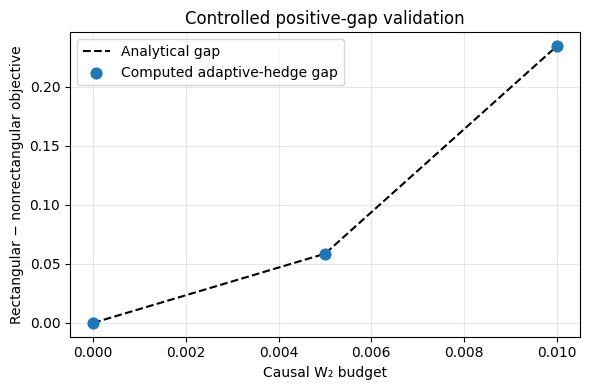

In [41]:
fig, ax = plt.subplots(figsize=(6, 4))

ax.plot(
    test_results["budget"],
    test_results["analytical_gap"],
    color="black",
    linestyle="--",
    label="Analytical gap",
)

ax.scatter(
    test_results["budget"],
    test_results["gap"],
    color="tab:blue",
    s=60,
    label="Computed adaptive-hedge gap",
    zorder=3,
)

ax.set_xlabel("Causal W₂ budget")
ax.set_ylabel("Rectangular − nonrectangular objective")
ax.set_title("Controlled positive-gap validation")
ax.grid(alpha=0.3)
ax.legend()

plt.tight_layout()
plt.show()